In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA # Importiamo la PCA, che useremo per ridurre le 4 caratteristiche dei pinguini a 2 dimensioni e visualizzare i dati in un grafico

# Leggiamo i file del progetto (tre tabelle), ed è proprio il comando read_csv ad aprire i file
specie = pd.read_csv("dati/penguins_metadata_eval.csv")
cluster = pd.read_csv("dati/penguins_cluster_assignments.csv")
bandwidth = pd.read_csv("dati/riepilogo_bandwidth.csv")

# Mostriamo le dimensioni dei file, e shape ci dice quante righe e colonne ci sono
print("Dimensioni del file delle specie:", specie.shape)
print("Dimensioni del file dei cluster:", cluster.shape)

Dimensioni del file delle specie: (342, 11)
Dimensioni del file dei cluster: (342, 3)


In [3]:
# Mostriamo le prime righe
print("\nPrime righe del file delle specie:")
print(specie.head())

print("\nPrime righe del file dei cluster:")
print(cluster.head())

# Dobbiamo conoscere le colonne, e facciamo questo perchè dobbiamo individuare la colonna che contiene le specie reali, e quelle che contengono le assegnazioni dei cluster
print("\nColonne del file delle specie:")
print(specie.columns.tolist())

print("\nColonne del file dei cluster:")
print(cluster.columns.tolist())


Prime righe del file delle specie:
   Original_Row_Index studyName  Sample Number Individual ID  \
0                   0   PAL0708              1          N1A1   
1                   1   PAL0708              2          N1A2   
2                   2   PAL0708              3          N2A1   
3                   4   PAL0708              5          N3A1   
4                   5   PAL0708              6          N3A2   

                               Species     Island     Sex  Culmen Length (mm)  \
0  Adelie Penguin (Pygoscelis adeliae)  Torgersen    MALE                39.1   
1  Adelie Penguin (Pygoscelis adeliae)  Torgersen  FEMALE                39.5   
2  Adelie Penguin (Pygoscelis adeliae)  Torgersen  FEMALE                40.3   
3  Adelie Penguin (Pygoscelis adeliae)  Torgersen  FEMALE                36.7   
4  Adelie Penguin (Pygoscelis adeliae)  Torgersen    MALE                39.3   

   Culmen Depth (mm)  Flipper Length (mm)  Body Mass (g)  
0               18.7             

In [4]:
# Controlliamo che i file contengano lo stesso numero di pinguini
print("\nNumero di pinguini nel file delle specie:", len(specie))
print("Numero di pinguini nel file dei cluster:", len(cluster))

# Controlliamo che gli indici dei pinguini corrispondano
indici_corrispondenti = (
    specie["Original_Row_Index"].equals(
        cluster["Original_Row_Index"]
    )
)

print("\nGli indici corrispondono?", indici_corrispondenti)


Numero di pinguini nel file delle specie: 342
Numero di pinguini nel file dei cluster: 342

Gli indici corrispondono? True


In [5]:
# Visualizziamo le specie presenti
print("\nSpecie presenti nel dataset:")
print(specie["Species"].value_counts())

# Confrontiamo le specie reali con i cluster ottenuti, e da qui iniziamo la validazione esterna

print("\nConfronto specie e cluster con bandwidth 2.0:")
tabella_h2 = pd.crosstab(
    specie["Species"],
    cluster["cluster_h2_0"]
)
print(tabella_h2)

print("\nConfronto specie e cluster con bandwidth 1.4:")
tabella_h1 = pd.crosstab(
    specie["Species"],
    cluster["cluster_h1_4"]
)
print(tabella_h1)


Specie presenti nel dataset:
Species
Adelie Penguin (Pygoscelis adeliae)          151
Gentoo penguin (Pygoscelis papua)            123
Chinstrap penguin (Pygoscelis antarctica)     68
Name: count, dtype: int64

Confronto specie e cluster con bandwidth 2.0:
cluster_h2_0                                 0    1
Species                                            
Adelie Penguin (Pygoscelis adeliae)        151    0
Chinstrap penguin (Pygoscelis antarctica)   67    1
Gentoo penguin (Pygoscelis papua)            0  123

Confronto specie e cluster con bandwidth 1.4:
cluster_h1_4                                 0    1   2
Species                                                
Adelie Penguin (Pygoscelis adeliae)        151    0   0
Chinstrap penguin (Pygoscelis antarctica)   32    2  34
Gentoo penguin (Pygoscelis papua)            0  123   0


In [6]:
# Calcoliamo l'Adjusted Rand Index (ARI)

ari_h2 = adjusted_rand_score(
    specie["Species"],
    cluster["cluster_h2_0"]
)

ari_h1 = adjusted_rand_score(
    specie["Species"],
    cluster["cluster_h1_4"]
)

print("\nAdjusted Rand Index:")
print("ARI con bandwidth 2.0:", round(ari_h2, 4))
print("ARI con bandwidth 1.4:", round(ari_h1, 4))

# Leggiamo le variabili standardizzate
dati_std = pd.read_csv("dati/penguins_meanshift_X_std.csv")

print("\nDimensioni dei dati standardizzati:")
print(dati_std.shape)

print("\nPrime righe dei dati standardizzati:")
print(dati_std.head())


Adjusted Rand Index:
ARI con bandwidth 2.0: 0.6535
ARI con bandwidth 1.4: 0.7751

Dimensioni dei dati standardizzati:
(342, 4)

Prime righe dei dati standardizzati:
   Culmen Length (mm)  Culmen Depth (mm)  Flipper Length (mm)  Body Mass (g)
0           -0.884499           0.785449            -1.418347      -0.564142
1           -0.811126           0.126188            -1.062250      -0.501703
2           -0.664380           0.430462            -0.421277      -1.188532
3           -1.324737           1.089724            -0.563715      -0.938776
4           -0.847812           1.748985            -0.777373      -0.689020


In [7]:
# Riduciamo le 4 variabili a 2 componenti principali
pca = PCA(n_components=2)

dati_pca = pca.fit_transform(dati_std)

print("\nDimensioni dei dati dopo la PCA:")
print(dati_pca.shape)

print("\nVarianza spiegata dalle due componenti:")
print(pca.explained_variance_ratio_)

print(
    "Varianza totale spiegata:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)


Dimensioni dei dati dopo la PCA:
(342, 2)

Varianza spiegata dalle due componenti:
[0.68843878 0.19312919]
Varianza totale spiegata: 88.16 %


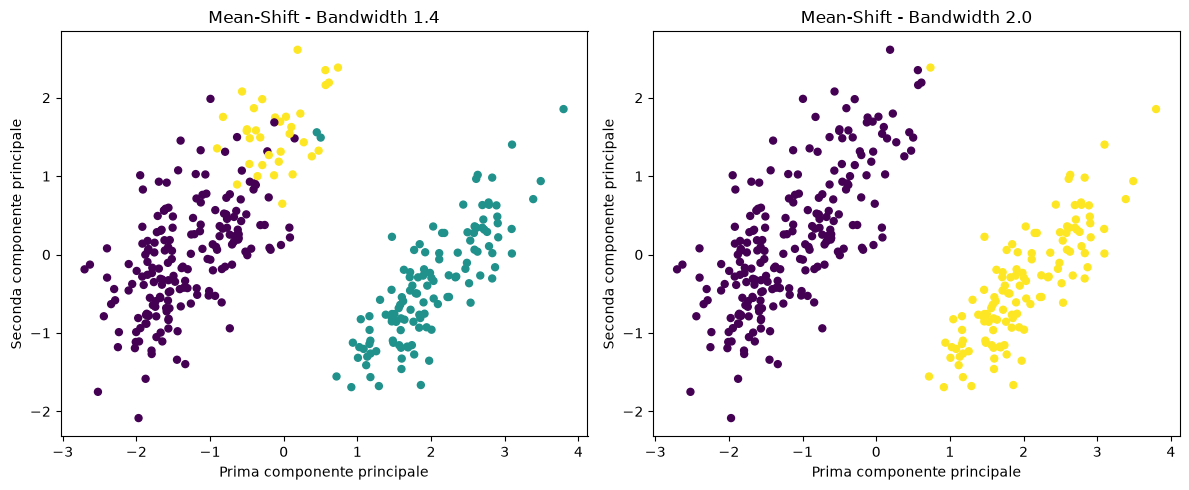

In [8]:
# Creiamo il grafico PCA per confrontare i cluster

plt.figure(figsize=(12, 5))

# Grafico con bandwidth 1.4
plt.subplot(1, 2, 1)

plt.scatter(
    dati_pca[:, 0],
    dati_pca[:, 1],
    c=cluster["cluster_h1_4"],
    cmap="viridis",
    s=25
)

plt.title("Mean-Shift - Bandwidth 1.4")
plt.xlabel("Prima componente principale")
plt.ylabel("Seconda componente principale")

# Grafico con bandwidth 2.0
plt.subplot(1, 2, 2)

plt.scatter(
    dati_pca[:, 0],
    dati_pca[:, 1],
    c=cluster["cluster_h2_0"],
    cmap="viridis",
    s=25
)

plt.title("Mean-Shift - Bandwidth 2.0")
plt.xlabel("Prima componente principale")
plt.ylabel("Seconda componente principale")

plt.tight_layout()
plt.show()